# 01 — Exploratory Data Analysis

**Problem.** Predict whether a borrower will experience *serious financial
distress* (90+ days delinquent) within two years — a binary classification used in
credit underwriting. Data: the **Give Me Some Credit** dataset (150,000 applicants),
loaded reproducibly from OpenML.

This notebook profiles the raw data: size, types, missingness, the class imbalance,
and the messy edges we'll have to clean — and ends with the questions that shape the
modeling.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import config, data
pd.set_option("display.width", 120)
plt.rcParams["figure.figsize"] = (8, 4.5)

df = data.load_raw()
print('shape:', df.shape)
df.head()

shape: (150000, 11)


,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents,default
0,0.029690,57,0,0.283244,10121.0,7,0,1,0,0.0,0
1,0.000000,57,0,0.142562,7750.0,9,0,1,0,0.0,0
2,0.036569,48,0,0.236294,6000.0,6,0,2,0,3.0,0
3,1.018331,41,0,0.163138,4958.0,4,0,0,0,0.0,0
4,1.008799,49,0,3942.000000,NaN,10,0,1,0,0.0,0


## Types and a structural profile

In [2]:
print(df.dtypes)
print('\nSummary statistics:')
df.describe().T.round(2)

RevolvingUtilizationOfUnsecuredLines    float64
age                                       int64
NumberOfTime30-59DaysPastDueNotWorse      int64
DebtRatio                               float64
MonthlyIncome                           float64
NumberOfOpenCreditLinesAndLoans           int64
NumberOfTimes90DaysLate                   int64
NumberRealEstateLoansOrLines              int64
NumberOfTime60-89DaysPastDueNotWorse      int64
NumberOfDependents                      float64
default                                   int64
dtype: object

Summary statistics:


,count,mean,std,min,25%,50%,75%,max
RevolvingUtilizationOfUnsecuredLines,150000.0,6.05,249.76,0.0,0.03,0.15,0.56,50708.0
age,150000.0,52.30,14.77,0.0,41.00,52.00,63.00,109.0
NumberOfTime30-59DaysPastDueNotWorse,150000.0,0.42,4.19,0.0,0.00,0.00,0.00,98.0
DebtRatio,150000.0,353.01,2037.82,0.0,0.18,0.37,0.87,329664.0
MonthlyIncome,120269.0,6670.22,14384.67,0.0,3400.00,5400.00,8249.00,3008750.0
NumberOfOpenCreditLinesAndLoans,150000.0,8.45,5.15,0.0,5.00,8.00,11.00,58.0
NumberOfTimes90DaysLate,150000.0,0.27,4.17,0.0,0.00,0.00,0.00,98.0
NumberRealEstateLoansOrLines,150000.0,1.02,1.13,0.0,0.00,1.00,2.00,54.0
NumberOfTime60-89DaysPastDueNotWorse,150000.0,0.24,4.16,0.0,0.00,0.00,0.00,98.0
NumberOfDependents,146076.0,0.76,1.12,0.0,0.00,0.00,1.00,20.0


## Class imbalance

The event we predict is **rare** — this is the first fact that shapes everything
(metrics, model settings, threshold).

Default rate: 0.0668  (10,026 of 150,000)
Imbalance ratio: 1 default per 15.0 applicants


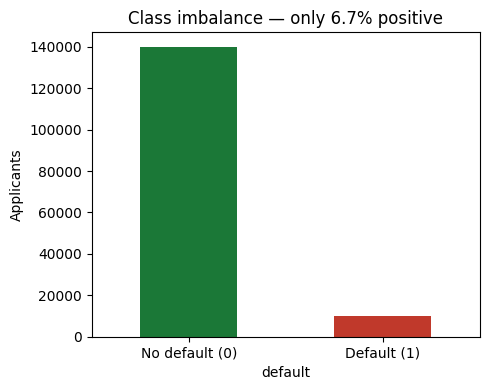

In [3]:
rate = df[config.TARGET].mean()
print(f'Default rate: {rate:.4f}  ({df[config.TARGET].sum():,} of {len(df):,})')
print(f'Imbalance ratio: 1 default per {1/rate:.1f} applicants')

fig, ax = plt.subplots(figsize=(5,4))
df[config.TARGET].value_counts().plot.bar(ax=ax, color=['#1b7837','#c0392b'])
ax.set_xticklabels(['No default (0)','Default (1)'], rotation=0)
ax.set_title(f'Class imbalance — only {rate*100:.1f}% positive')
ax.set_ylabel('Applicants'); plt.tight_layout(); plt.show()

**Implication:** accuracy is useless here (predicting "no default" for
everyone scores ~93%). We'll evaluate with **ROC-AUC and PR-AUC** and handle the
imbalance explicitly (notebook 02/03).

## Missingness

MonthlyIncome         19.82%  (
NumberOfDependents     2.62%  (
dtype: object MonthlyIncome         29731
NumberOfDependents     3924
dtype: object rows)


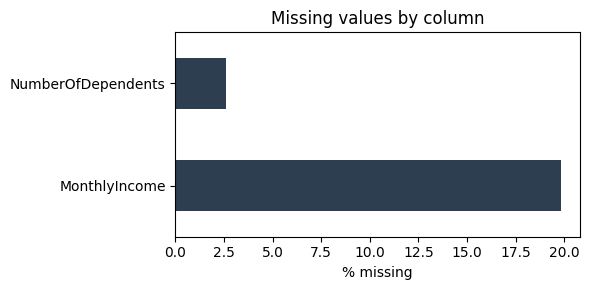

In [4]:
miss = df.isna().sum()
miss = miss[miss > 0]
print((miss / len(df) * 100).round(2).astype(str) + '%  (', miss.astype(str), 'rows)')
fig, ax = plt.subplots(figsize=(6,3))
(miss/len(df)*100).plot.barh(ax=ax, color='#2c3e50')
ax.set_xlabel('% missing'); ax.set_title('Missing values by column'); plt.tight_layout(); plt.show()

`MonthlyIncome` (~20%) and `NumberOfDependents` (~2.6%) are missing.
Income is plausibly **not missing at random** (people without steady income may skip
it), so we'll add a missingness *flag* rather than silently imputing it away.

## The messy edges (outliers & data glitches)

In [5]:
# Heavy tails: utilization and debt ratio have absurd maxima.
print('RevolvingUtilization > 1 :', (df['RevolvingUtilizationOfUnsecuredLines']>1).sum(),
      '| max:', df['RevolvingUtilizationOfUnsecuredLines'].max())
print('DebtRatio max:', df['DebtRatio'].max())
print('age == 0 rows:', (df['age']==0).sum())

# The past-due columns contain sentinel glitch values 96 and 98.
pastdue = ['NumberOfTime30-59DaysPastDueNotWorse','NumberOfTime60-89DaysPastDueNotWorse','NumberOfTimes90DaysLate']
print('\nPast-due value glitches (96/98 are data errors):')
for col in pastdue:
    vc = df[col].value_counts()
    print(f'  {col}: 96 ->', int(vc.get(96,0)), '| 98 ->', int(vc.get(98,0)))

RevolvingUtilization > 1 : 3321 | max: 50708.0
DebtRatio max: 329664.0
age == 0 rows: 1

Past-due value glitches (96/98 are data errors):
  NumberOfTime30-59DaysPastDueNotWorse: 96 -> 5 | 98 -> 264
  NumberOfTime60-89DaysPastDueNotWorse: 96 -> 5 | 98 -> 264
  NumberOfTimes90DaysLate: 96 -> 5 | 98 -> 264


Three concrete data-quality issues to fix in preprocessing:
1. **Heavy-tailed ratios** — `RevolvingUtilization` up to 50,708 and `DebtRatio` up to
   329,664 are implausible; we'll winsorize.
2. **`age = 0`** — one impossible row; clip to a sane minimum.
3. **Past-due `96`/`98`** — a documented data-entry glitch; cap to a realistic max.

In [6]:
# Default rate rises steeply with past-due history — a strong, sensible signal.
tmp = df.copy()
tmp['any_pastdue'] = (tmp[pastdue].clip(upper=20).sum(axis=1) > 0)
print(tmp.groupby('any_pastdue')[config.TARGET].mean().round(3))

any_pastdue
False    0.027
True     0.223
Name: default, dtype: float64


## Initial questions for modeling
1. Which features actually drive default? (past-due history and utilization look strong)
2. How much does the missing-income flag matter?
3. Can a simple logistic model compete with gradient boosting, and at what cost to AUC?
4. Where should the decision threshold sit given that a missed default is far costlier
   than a wrongly rejected applicant?

**Next:** `02_preprocessing` turns these raw quirks into clean, modeling-ready
features — documenting every decision.